### 1. Descarga y Carga de la Imagen de Pikachu
Primero, importamos las librerías necesarias (`numpy`, `matplotlib`, `PIL`, `requests`) y descargamos una imagen de Pikachu para trabajar con ella.

Dimensiones de la imagen original a color (Alto, Ancho, Canales): (224, 224, 3)


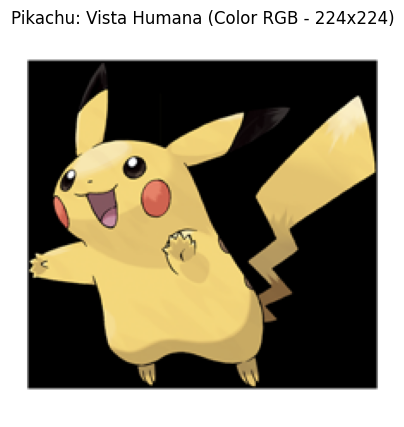

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import requests
from io import BytesIO

# URL de una imagen de Pikachu
url = "https://raw.githubusercontent.com/PokeAPI/sprites/master/sprites/pokemon/other/official-artwork/25.png"
response = requests.get(url)

# Descargar y redimensionar directamente a 224x224 (Estándar para modelos de IA)
img = Image.open(BytesIO(response.content)).convert("RGB").resize((224, 224))

# Convertir a array de numpy (Cubo de datos: 224 x 224 x 3 Canales)
img_np = np.array(img)

print(f"Dimensiones de la imagen original a color (Alto, Ancho, Canales): {img_np.shape}")
plt.figure(figsize=(5, 5))
plt.imshow(img_np)
plt.title("Pikachu: Vista Humana (Color RGB - 224x224)")
plt.axis('off')
plt.show()

### 2. Conversión a Escala de Grises
Para una IA, procesar tres canales (R, G, B) requiere tres veces más cálculos que procesar un solo canal. Al convertir la imagen a escala de grises, reducimos las dimensiones de la matriz de `(Alto, Ancho, 3)` a simplemente `(Alto, Ancho)`. Cada píxel ahora se representa con un único número del 0 (negro) al 255 (blanco).

Nuevas dimensiones de la imagen en escala de grises (Alto, Ancho): (224, 224)


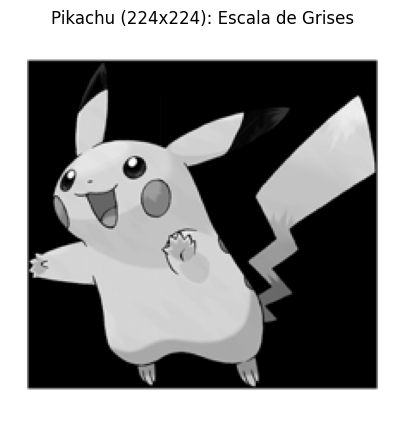

In [ ]:
# Convertir a escala de grises usando la fórmula de luminancia estándar
img_gray = np.dot(img_np[...,:3], [0.299, 0.587, 0.114]).astype(np.uint8)

print(f"Nuevas dimensiones de la imagen en escala de grises (Alto, Ancho): {img_gray.shape}")

plt.figure(figsize=(5, 5))
plt.imshow(img_gray, cmap='gray')
plt.title("Pikachu (224x224): Escala de Grises")
plt.axis('off')
plt.show()

### 3. La Perspectiva de la Máquina: El Vector Numérico
Una IA no "ve" formas ni colores; ve matrices numéricas. Vamos a extraer una pequeña sección de la mejilla o el cuerpo de Pikachu (una cuadrícula de 15x15 píxeles) y mostraremos tanto la imagen ampliada como la matriz de números reales que la componen.

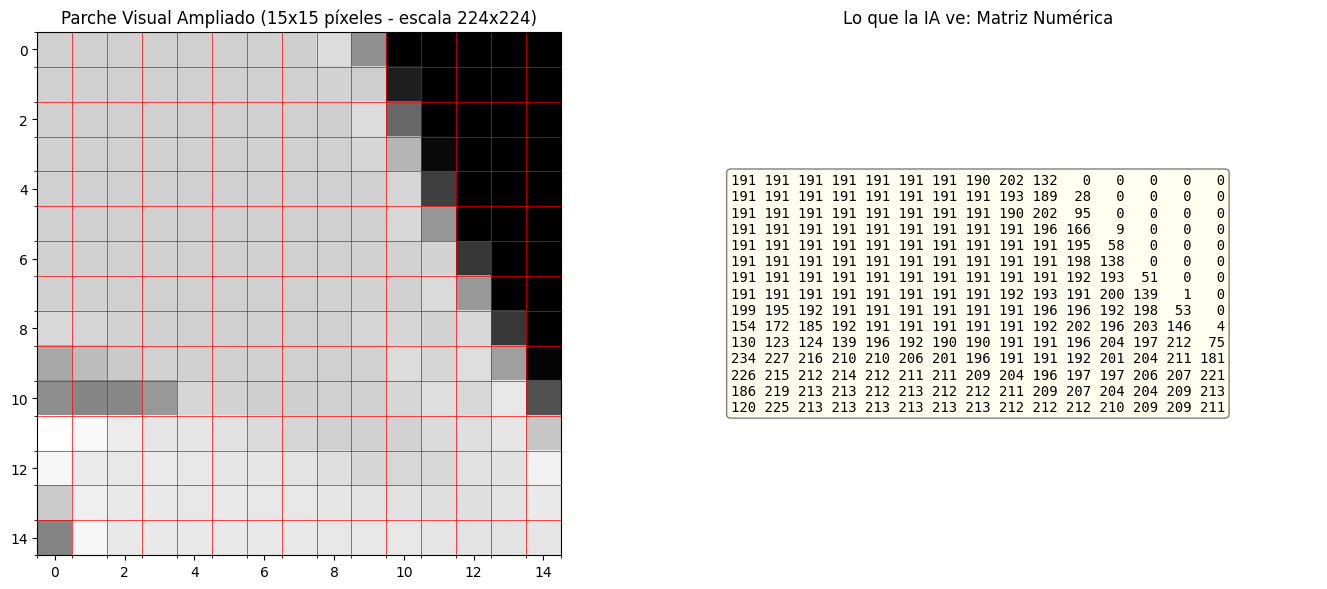

In [ ]:
# Al haber cambiado la resolución a 224x224, recalculamos el centro de la imagen
alto, ancho = img_gray.shape
centro_y, centro_x = alto // 2, ancho // 2

# Extraemos un parche de 15x15 píxeles del rostro de Pikachu
parche = img_gray[centro_y-7:centro_y+8, centro_x-7:centro_x+8]

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Mostrar el parche visualmente
axes[0].imshow(parche, cmap='gray', interpolation='nearest')
axes[0].set_title("Parche Visual Ampliado (15x15 píxeles - escala 224x224)")
axes[0].set_xticks(np.arange(-0.5, 15, 1), minor=True)
axes[0].set_yticks(np.arange(-0.5, 15, 1), minor=True)
axes[0].grid(which='minor', color='red', linestyle='-', linewidth=0.5)

# Mostrar la matriz numérica
axes[1].axis('off')
matriz_texto = "\n".join([" ".join([f"{val:3d}" for val in fila]) for fila in parche])
axes[1].text(0.5, 0.5, matriz_texto, fontsize=10, family='monospace',
             ha='center', va='center', bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.5))
axes[1].set_title("Lo que la IA ve: Matriz Numérica")

plt.tight_layout()
plt.show()

### 4. Histograma de la Imagen
Un histograma de frecuencias nos permite analizar la distribución de todos los tonos de gris de la imagen. Esto ayuda a la IA a comprender si la imagen es generalmente oscura, clara o si tiene mucho contraste.

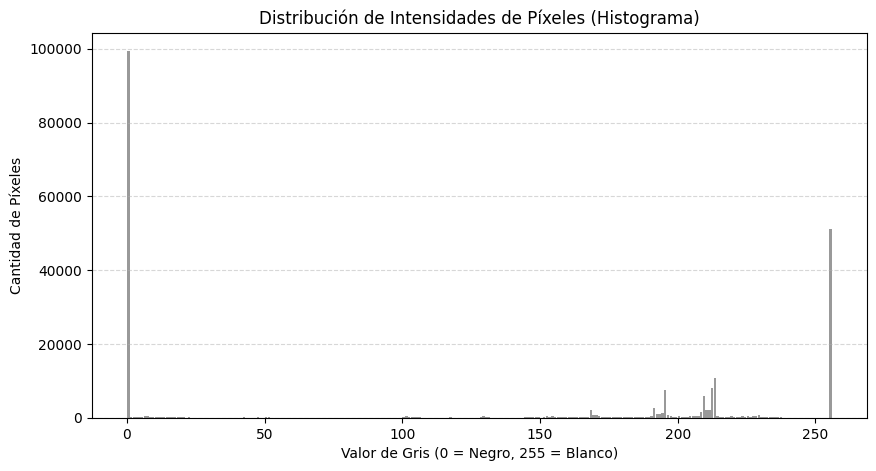

In [ ]:
plt.figure(figsize=(10, 5))

# Generar el histograma
# .ravel() aplana la matriz bidimensional en un vector unidimensional de píxeles
plt.hist(img_gray.ravel(), bins=256, range=(0, 256), color='gray', alpha=0.8, rwidth=0.9)

plt.title("Distribución de Intensidades de Píxeles (Histograma)")
plt.xlabel("Valor de Gris (0 = Negro, 255 = Blanco)")
plt.ylabel("Cantidad de Píxeles")
plt.grid(axis='y', linestyle='--', alpha=0.5)

plt.show()

### 5. Representación Numérica de la Imagen Completa
Para poder visualizar la totalidad de Pikachu como una cuadrícula de números legible, reduciremos temporalmente la escala de la imagen de grises a una resolución de **28x28** (el tamaño clásico usado en redes como LeNet/MNIST). Esto nos permite imprimir de forma visual y exacta el mapa numérico completo de la silueta de Pikachu.

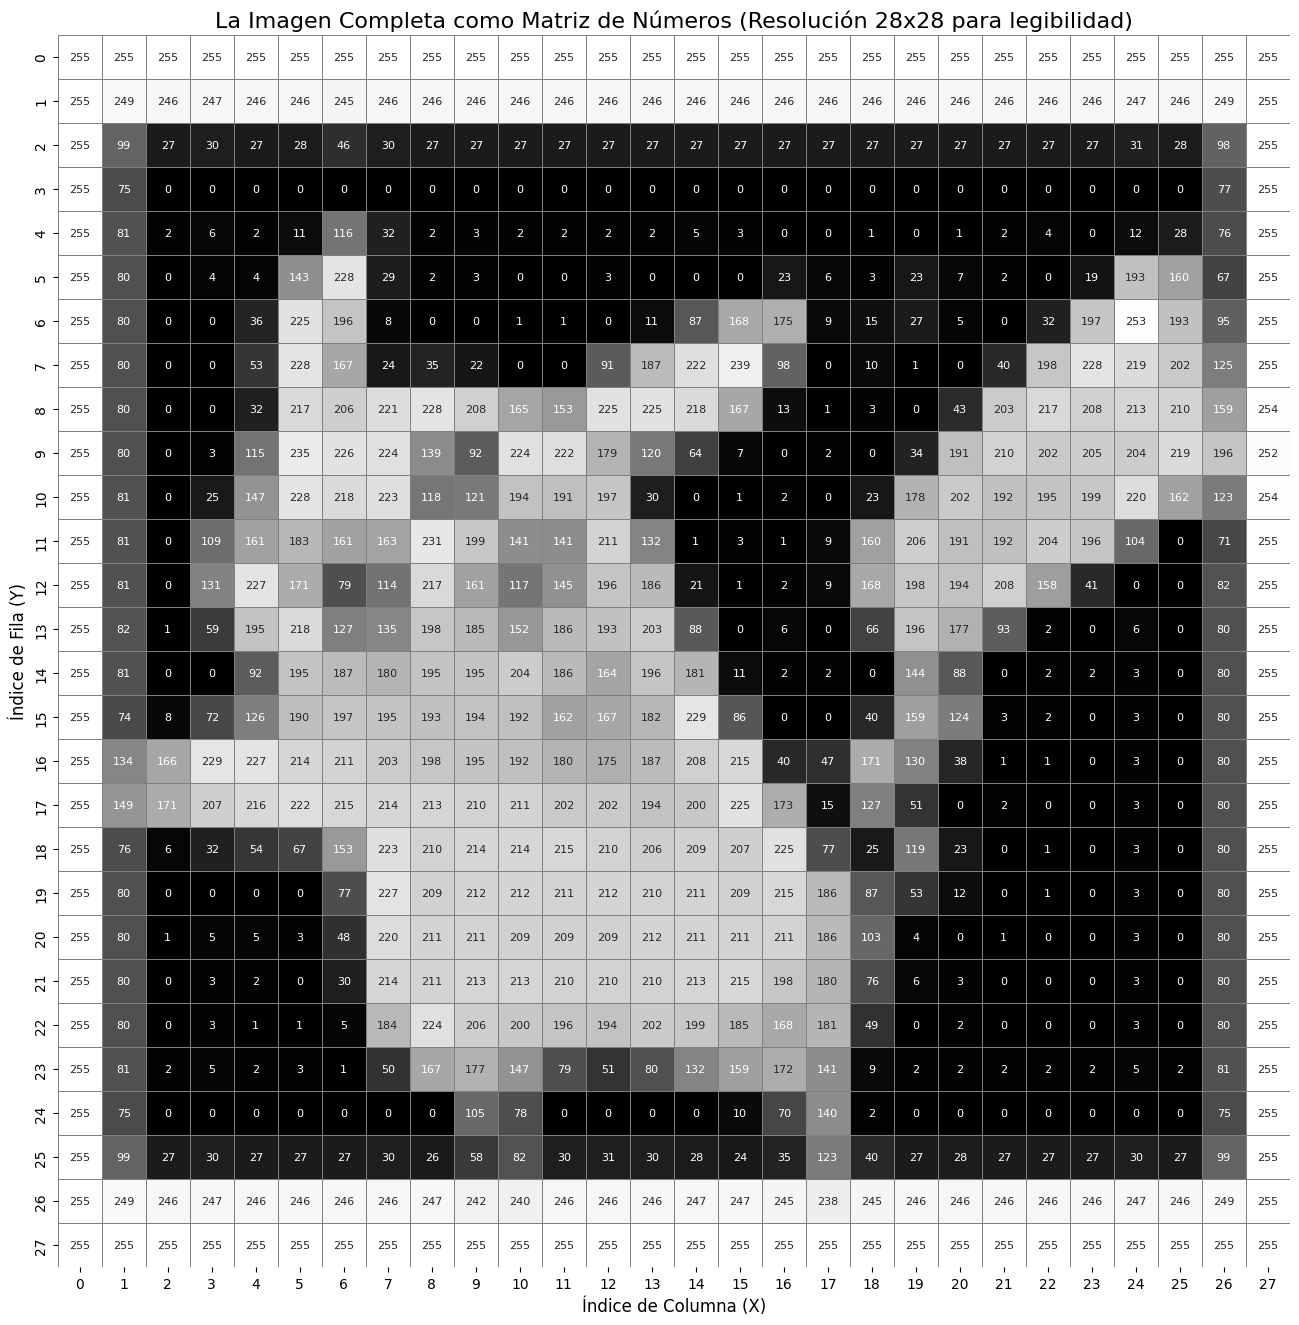

In [ ]:
import seaborn as sns

# Redimensionar la imagen de grises completa a 28x28 usando PIL para conservar la silueta de Pikachu
img_pil_gray = Image.fromarray(img_gray)
img_mini = img_pil_gray.resize((28, 28), Image.Resampling.LANCZOS)
img_mini_np = np.array(img_mini)

# Crear un mapa de calor gigante con los valores numéricos de todos los píxeles de la imagen
plt.figure(figsize=(20, 16))
sns.heatmap(img_mini_np, annot=True, fmt="d", cmap="gray", cbar=False, square=True,
            annot_kws={"size": 8}, linewidths=0.5, linecolor="gray")

plt.title("La Imagen Completa como Matriz de Números (Resolución 28x28 para legibilidad)", fontsize=16)
plt.xlabel("Índice de Columna (X)", fontsize=12)
plt.ylabel("Índice de Fila (Y)", fontsize=12)
plt.show()

### 6. Mapa de Calor Interactivo (Matriz 28x28)
Utilizando la librería `plotly`, crearemos un gráfico interactivo. Puedes pasar el cursor por encima de cada celda para descubrir el valor exacto del píxel que la máquina procesa.

In [ ]:
import plotly.graph_objects as go

# Invertir verticalmente la matriz para que coincida con la orientación del gráfico estándar de imagen
matriz_espejo = np.flipud(img_mini_np)

fig = go.Figure(data=go.Heatmap(
    z=matriz_espejo,
    colorscale='Gray',
    showscale=True,
    hoverongaps=False,
    hovertemplate='Columna (X): %{x}<br>Fila (Y): %{y}<br>Valor de Gris: %{z}<extra></extra>'
))

fig.update_layout(
    title='Mapa de Calor Interactivo del Pikachu Completo (Pasa el cursor sobre los píxeles)',
    xaxis=dict(title='Índice de Columna (X)', dtick=1),
    yaxis=dict(title='Índice de Fila (Y)', dtick=1),
    width=800,
    height=800,
    autosize=False
)

fig.show()